In [13]:
import numpy as np
from numpy import pi

from qiskit import QuantumRegister, ClassicalRegister, QuantumCircuit
from qiskit.quantum_info import Operator, Statevector
from qiskit.visualization import (
    array_to_latex,
    plot_histogram,
    plot_distribution
)

from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

In [ ]:
MiToken = "###"
MiInstance = "###"
Channel = "ibm_cloud"

In [15]:

# Conexión al servicio IBM Quantum
service = QiskitRuntimeService(
    channel=Channel,
    token=MiToken,
    instance=MiInstance
)

# Selección de un procesador cuántico real
IBMQProcessor = service.least_busy(
    operational=True,
    simulator=False,
    min_num_qubits=3
)

print("Procesador seleccionado:", IBMQProcessor.name)
print("Número de qubits:", IBMQProcessor.num_qubits)

qiskit_runtime_service._discover_account:WARNING:2026-10-09 02:34:20,627: Loading account with the given token. A saved account will not be used.


Procesador seleccionado: ibm_marrakesh
Número de qubits: 156


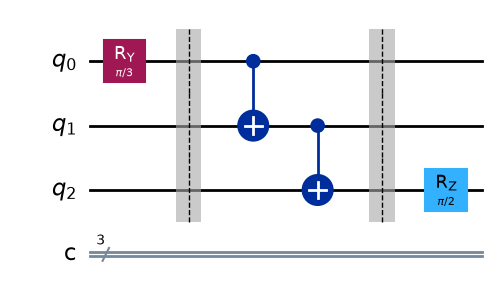

In [16]:
qreg_q = QuantumRegister(3, 'q')
creg_c = ClassicalRegister(3, 'c')

circuit = QuantumCircuit(qreg_q, creg_c)

theta = pi / 3
phi = pi / 2

circuit.ry(theta, qreg_q[0])

circuit.barrier()

circuit.cx(qreg_q[0], qreg_q[1])
circuit.cx(qreg_q[1], qreg_q[2])

circuit.barrier()

circuit.rz(phi, qreg_q[2])

display(circuit.draw('mpl'))

In [17]:
unitary = Operator(circuit)

display(
    array_to_latex(
        unitary.data,
        precision=3,
        prefix=r"U_{\mathrm{circuito}}="
    )
)

<IPython.core.display.Latex object>

In [18]:
final_state = Statevector(circuit)

display(
    array_to_latex(
        final_state.data,
        precision=5,
        prefix=r"|\psi_f\rangle="
    )
)

<IPython.core.display.Latex object>

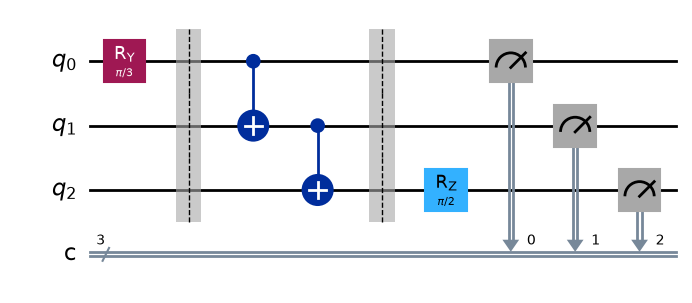

In [19]:
circuit.measure(qreg_q, creg_c)

display(circuit.draw('mpl'))

In [20]:
circuit_teorico = circuit.remove_final_measurements(inplace=False)

estado = Statevector(circuit_teorico)

print("Probabilidades teóricas:")
print(estado.probabilities_dict())

Probabilidades teóricas:
{np.str_('000'): np.float64(0.7499999999999999), np.str_('111'): np.float64(0.2499999999999999)}


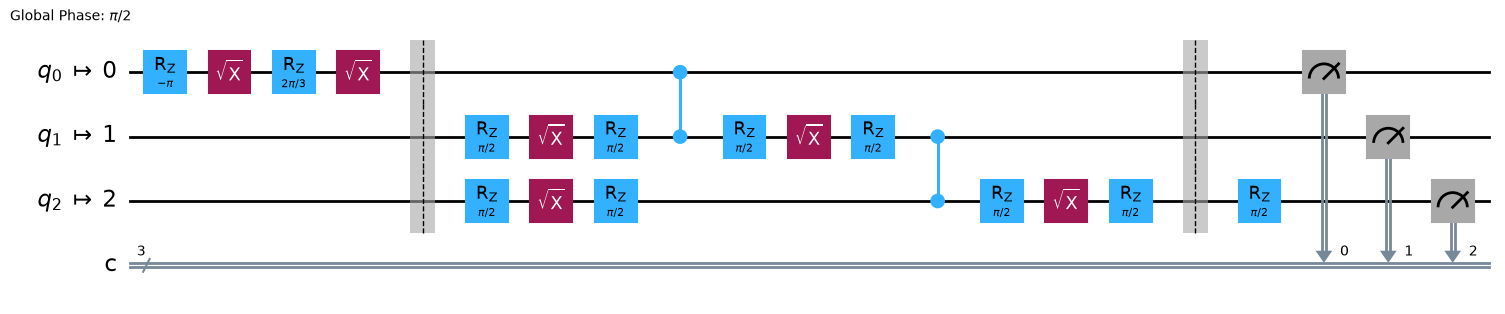

In [21]:
pm = generate_preset_pass_manager(
    optimization_level=1,
    backend=IBMQProcessor
)

isa_circuit = pm.run(circuit)

display(isa_circuit.draw('mpl', idle_wires=False))

In [22]:
sampler = SamplerV2(mode=IBMQProcessor)

shots = 1024

job = sampler.run(
    [isa_circuit],
    shots=shots
)

print("Job ID:", job.job_id())

/tmp/ipykernel_2207/1046402296.py:1: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler = SamplerV2(mode=IBMQProcessor)


Job ID: db455hslf4us73c27lo0


In [23]:
result = job.result()

pub_result = result[0]

counts = pub_result.data.c.get_counts()

print("Resultados experimentales:")
print(counts)

Resultados experimentales:
{'000': 756, '110': 9, '111': 248, '011': 1, '100': 3, '010': 2, '101': 3, '001': 2}


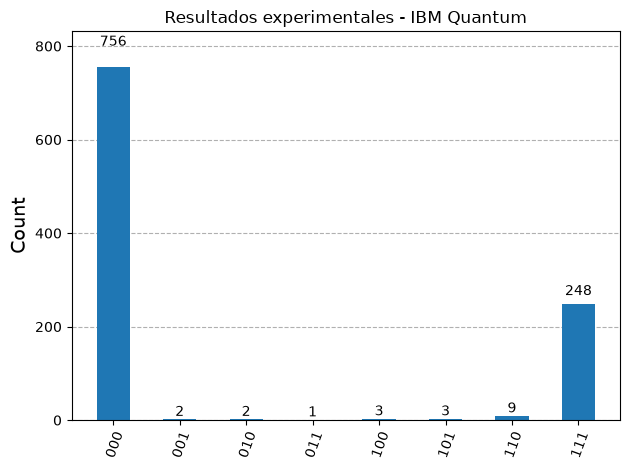

In [24]:
display(
    plot_histogram(
        counts,
        title="Resultados experimentales - IBM Quantum"
    )
)

In [27]:
import numpy as np

# Estados computacionales de los 3 qubits
estados = [format(i, '03b') for i in range(8)]

# Probabilidades teóricas
prob_teoricas = final_state.probabilities_dict()

p_teo = np.array([
    prob_teoricas.get(e, 0) for e in estados
], dtype=float)

# Probabilidades experimentales
total = sum(counts.values())

p_exp = np.array([
    counts.get(e, 0) / total for e in estados
])

# Métricas de error
MAE = np.mean(np.abs(p_teo - p_exp))
MSE = np.mean((p_teo - p_exp)**2)
RMSE = np.sqrt(MSE)

print("===== MÉTRICAS DE ERROR =====")
print(f"MAE:  {MAE:.6f}")
print(f"MSE:  {MSE:.6f}")
print(f"RMSE: {RMSE:.6f}")

===== MÉTRICAS DE ERROR =====
MAE:  0.004883
MSE:  0.000038
RMSE: 0.006138


In [30]:
mit = mthree.M3Mitigation(IBMQProcessor)
mit.cals_from_system([0, 1, 2])

mitigate_quasi = mit.apply_correction(counts, [0, 1, 2])
mitigate_probs = mitigate_quasi.nearest_probability_distribution()

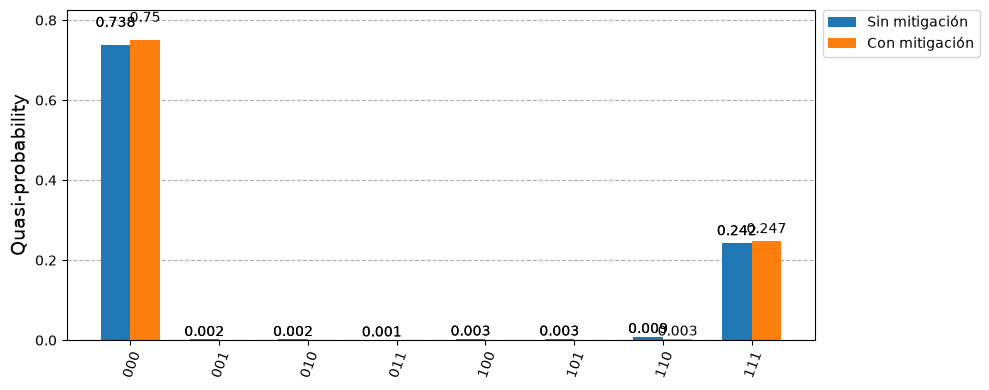

In [32]:
prob_originales = {
    estado: valor / sum(counts.values())
    for estado, valor in counts.items()
}

plot_distribution(
    [prob_originales, mitigate_probs],
    figsize=(10, 4),
    legend=['Sin mitigación', 'Con mitigación']
)

In [33]:
# Probabilidades mitigadas
p_mitigado = np.array([
    mitigate_probs.get(estado, 0) for estado in estados
])

# Métricas de error con mitigación
MAE_mit = np.mean(np.abs(p_teo - p_mitigado))
MSE_mit = np.mean((p_teo - p_mitigado)**2)
RMSE_mit = np.sqrt(MSE_mit)

print("===== ERRORES CON MITIGACIÓN =====")
print(f"MAE:  {MAE_mit:.6f}")
print(f"MSE:  {MSE_mit:.6f}")
print(f"RMSE: {RMSE_mit:.6f}")

===== ERRORES CON MITIGACIÓN =====
MAE:  0.000732
MSE:  0.000002
RMSE: 0.001389
